In [9]:
from plotting_helpers import get_job_table_df
from peacsim.parsing import job_profile_reader as job_parser
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# weigts_file_path = "../output/optimization/Wtrain_low_util_EDR_1000server_20250311133508/opt_weights.csv"

exp_name = "indiv_W10_0.7_20250422130801"

output_dir = "../output/simulation/" + exp_name

job_config = "W10.ini"

job_config = job_parser.JobProfileReader("../../../configs/workload/" + job_config)

In [11]:
job_table = get_job_table_df(output_dir)

In [12]:
def plot_cdf(qos_data, qos_constraint, job_type_id, job_name):
    plt.figure(figsize=(4, 3))

    # Increase global font size
    plt.rcParams.update({'font.size': 14})  # Adjust the number as needed

    sns.ecdfplot(qos_data, color='orange')

    # Add the 90th percentile line
    plt.axhline(0.9, color='green', linestyle='--', linewidth=2, label='90th %ile')

    # Add the QoS threshold line
    plt.axvline(qos_constraint, color='red', linestyle='--', linewidth=2, label='Q_thres')

    # Set labels with increased font size
    plt.ylabel("CDF", fontsize=16)
    plt.xlabel(job_name, fontsize=16)
    plt.legend(fontsize=14)  # Increase legend font size

    # Save the plot
    plt.savefig('plots/qos_cdf_job_type' + str(job_type_id) + '.png', bbox_inches='tight')
import matplotlib.pyplot as plt
import seaborn as sns

def plot_cdf_2x2(qos_data_list, qos_constraints, job_names, job_type_ids):
    fig, axes = plt.subplots(2, 2, figsize=(8, 6))  # 2x2 grid

    # Increase global font size
    plt.rcParams.update({'font.size': 14})

    # Flatten axes for easier iteration
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        sns.ecdfplot(qos_data_list[i], color='orange', ax=ax)

        # Add the 90th percentile line
        ax.axhline(0.9, color='green', linestyle='--', linewidth=2)

        # Add the QoS threshold line
        ax.axvline(qos_constraints[i], color='red', linestyle='--', linewidth=2)

        # Set labels
        ax.set_ylabel("CDF", fontsize=14)
        ax.set_xlabel(job_names[i], fontsize=14)

    # Create a single legend for all plots
    handles = [
        plt.Line2D([0], [0], color='orange', linewidth=2, label="CDF"),
        plt.Line2D([0], [0], color='green', linestyle='--', linewidth=2, label="90th %ile"),
        plt.Line2D([0], [0], color='red', linestyle='--', linewidth=2, label="Q_thres")
    ]

    fig.legend(handles=handles, loc='upper center', fontsize=14, ncol=3, bbox_to_anchor=(0.5, 1.05))

    plt.tight_layout()
    plt.savefig('plots/qos_cdf_2x2.png', bbox_inches='tight')
    plt.show()


Jobtype 2 Violate QoS. 3.921052631578948 > 3.1
Jobtype 6 Violate QoS. 4.777777777777778 > 4.5
QoS 90 deg by job type
job_type_id
0    1.984869
1    1.500000
2    3.947368
3    0.756556
4    1.487234
5    1.625704
6    4.805556
7    1.111585
dtype: float64


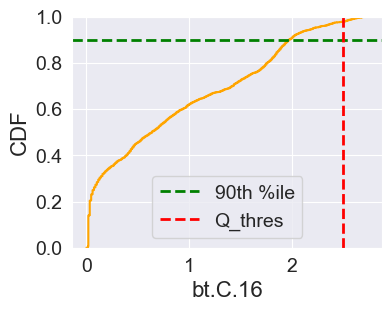

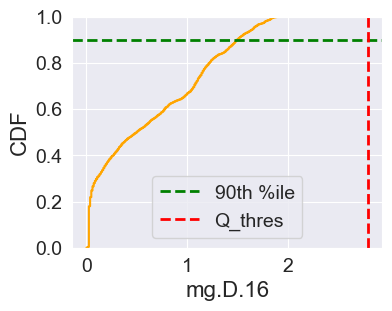

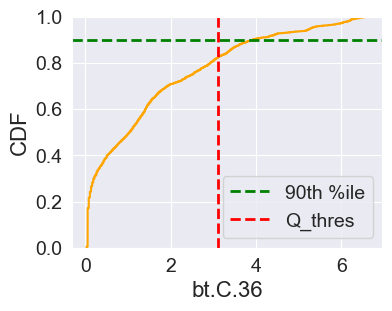

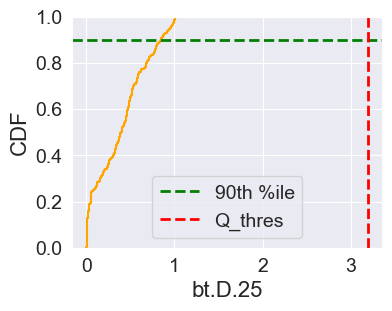

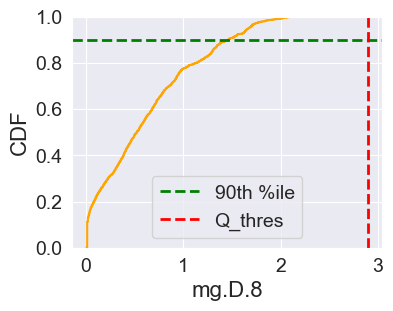

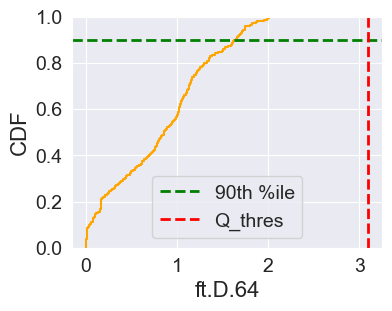

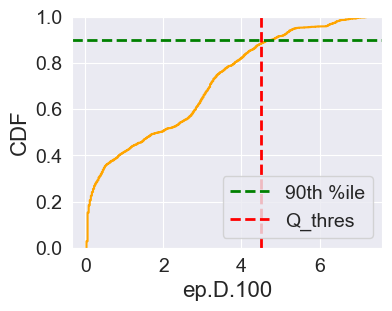

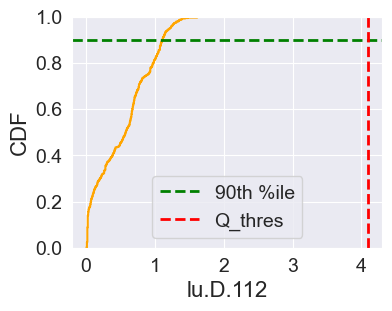

In [13]:
violate_qos = []
qos_constraints = job_config.all_job_qos_constraints
job_not_ended = -1

for job_type in range(job_config.job_type_count):
    qos_violate = 0
    current_job_type = job_table[
        (job_table['job_type_id'] == job_type) & (job_table['arrival_time'] <= 18000)]
    realtime_qos_list = list(current_job_type['realtime_qos'])
    plot_cdf(realtime_qos_list, qos_constraints[job_type], job_type, job_config.all_jobs[job_type])
    if len(realtime_qos_list) > 0:
        qos_deg_sort = np.sort(realtime_qos_list)
        qos_deg_at_90 = qos_deg_sort[int(0.9 * len(qos_deg_sort))]
        if qos_deg_at_90 > qos_constraints[job_type]:
            qos_violate = 1
            print(f'Jobtype {job_type} Violate QoS. {qos_deg_at_90} > {qos_constraints[job_type]}')
    violate_qos.append(qos_violate)  # may be used for setting P,R of next phase.

# plot_cdf_2x2()
qos_violations = sum(violate_qos)

started_jobs = job_table[
    (job_table['end_time'] > job_not_ended) & (job_table['arrival_time'] < 18000)]

qos = started_jobs.groupby('job_type_id').apply(
    lambda x: (x['end_time'] - x['arrival_time'] - x['min_execution_time']) / x['min_execution_time'])
print('QoS 90 deg by job type')
q90deg = qos.groupby('job_type_id').quantile(0.9)
print(q90deg)

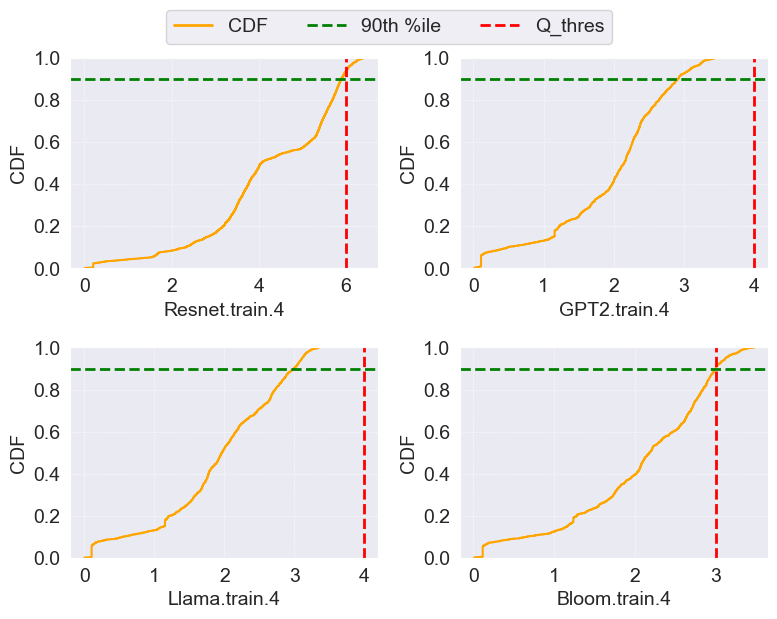

In [8]:
def plot_cdf_2x2(qos_data_list, qos_constraints, job_names):
    """Plots 2x2 CDF graphs with a single legend."""

    fig, axes = plt.subplots(2, 2, figsize=(8, 6))  # 2x2 grid
    plt.rcParams.update({'font.size': 14})  # Increase global font size
    axes = axes.flatten()  # Flatten the axes for easier indexing

    for i, ax in enumerate(axes):
        plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

        if i < len(qos_data_list):  # Ensure we don't exceed available data
            sns.ecdfplot(qos_data_list[i], color='orange', ax=ax)
            ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

            ax.axhline(0.9, color='green', linestyle='--', linewidth=2)
            ax.axvline(qos_constraints[i], color='red', linestyle='--', linewidth=2)
            ax.set_ylabel("CDF", fontsize=14)
            ax.set_xlabel(job_names[i], fontsize=14)

    # Create a single legend
    handles = [
        plt.Line2D([0], [0], color='orange', linewidth=2, label="CDF"),
        plt.Line2D([0], [0], color='green', linestyle='--', linewidth=2, label="90th %ile"),
        plt.Line2D([0], [0], color='red', linestyle='--', linewidth=2, label="Q_thres")
    ]
    fig.legend(handles=handles, loc='upper center', fontsize=14, ncol=3, bbox_to_anchor=(0.5, 1.05))

    plt.tight_layout()
    plt.savefig('plots/qos_cdf_2x2.png', bbox_inches='tight', dpi=600)
    plt.show()


# ---- Integration with Your QoS Analysis ----
violate_qos = []
qos_constraints = job_config.all_job_qos_constraints
job_not_ended = -1

qos_data_list = []  # Stores data for 2x2 plotting
job_names = []  # Stores job names for labels

for job_type in range(job_config.job_type_count):
    qos_violate = 0
    current_job_type = job_table[
        (job_table['job_type_id'] == job_type) & (job_table['arrival_time'] <= 18000)]

    realtime_qos_list = list(current_job_type['realtime_qos'])
    qos_data_list.append(realtime_qos_list)  # Collect for plotting
    job_names.append(job_config.all_jobs[job_type])  # Collect job names

    # QoS Violation Check
    if len(realtime_qos_list) > 0:
        qos_deg_sort = np.sort(realtime_qos_list)
        qos_deg_at_90 = qos_deg_sort[int(0.9 * len(qos_deg_sort))]
        if qos_deg_at_90 > qos_constraints[job_type]:
            qos_violate = 1
            print(f'Jobtype {job_type} Violate QoS. {qos_deg_at_90} > {qos_constraints[job_type]}')

    violate_qos.append(qos_violate)  # Track violations

# ---- Generate Single 2x2 CDF Plot ----
plot_cdf_2x2(qos_data_list, qos_constraints, job_names)


In [48]:
job_type_counts = job_table.groupby('job_type_id').size().reset_index(name='counts')
print(job_type_counts)

   job_type_id  counts
0            0    8334
1            1    2553
2            2    2389
3            3    2718


22604

22866

In [42]:
3600 * 5

18000